In [1]:

import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)


Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python location: C:\Users\valat\AppData\Local\Programs\Python\Python312\python.exe


In [2]:

%pip install pandas numpy matplotlib scikit-learn ucimlrepo openpyxl


  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv("default of credit card clients.csv")

print("Dataset loaded successfully!")
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

display(data.head())


Dataset loaded successfully!
Number of rows: 30000
Number of columns: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,dpnm
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:

# Dataset structure
print("Dataset shape:", data.shape)

# Column names
print("\nColumns:")
print(data.columns.tolist())

# Missing values
print("\nTotal missing values:", data.isnull().sum().sum())

# Duplicate rows
print("Duplicate rows:", data.duplicated().sum())

# Target distribution
print("\nTarget distribution:")
print(data["dpnm"].value_counts().sort_index())

print("\nTarget percentages:")
print((data["dpnm"].value_counts(normalize=True).sort_index() * 100).round(2))


Dataset shape: (30000, 25)

Columns:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'dpnm']

Total missing values: 0
Duplicate rows: 0

Target distribution:
dpnm
0    23364
1     6636
Name: count, dtype: int64

Target percentages:
dpnm
0    77.88
1    22.12
Name: proportion, dtype: float64


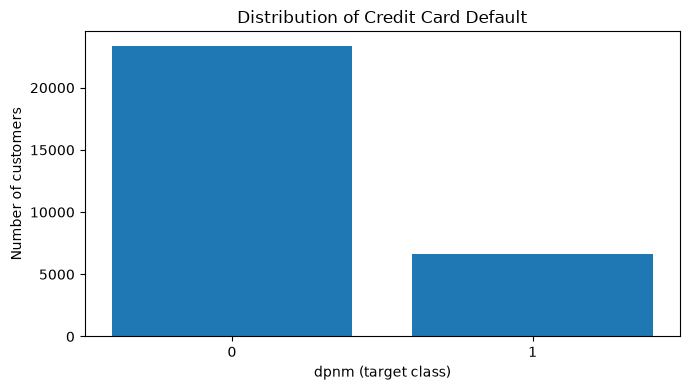

In [6]:

target_counts = data["dpnm"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(
    target_counts.index.astype(str),
    target_counts.values
)

plt.title("Distribution of Credit Card Default")
plt.xlabel("dpnm (target class)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


In [7]:

# Cell 6A: Summary statistics

display(data.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.50,8660.40,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0


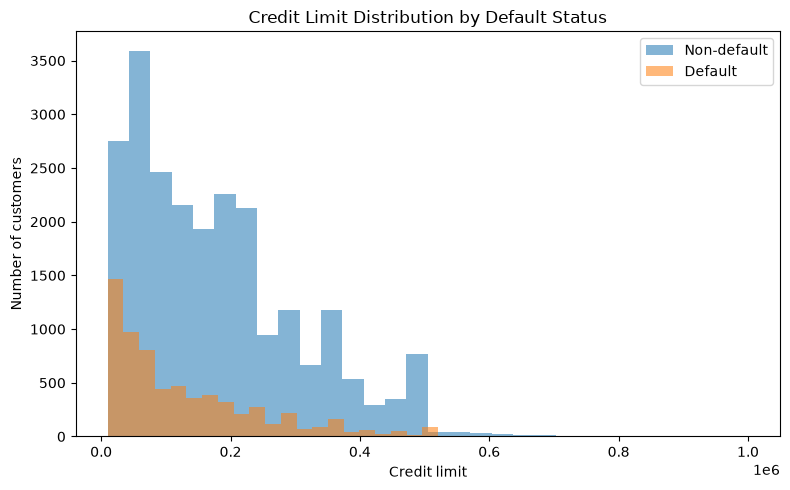

In [8]:

# Cell 6B: Credit limit distribution by default status

plt.figure(figsize=(8, 5))

for status, label in [(0, "Non-default"), (1, "Default")]:
    values = data.loc[data["dpnm"] == status, "LIMIT_BAL"]
    plt.hist(
        values,
        bins=30,
        alpha=0.55,
        label=label
    )

plt.xlabel("Credit limit")
plt.ylabel("Number of customers")
plt.title("Credit Limit Distribution by Default Status")
plt.legend()
plt.tight_layout()
plt.show()


In [10]:

# Cell 6C: Default rate by recent repayment status

default_by_pay = data.groupby("PAY_1")["dpnm"].agg(
    Customers="count",
    Defaults="sum",
    Default_Rate="mean"
)

default_by_pay["Default_Rate"] *= 100

display(default_by_pay.round(2))


,Customers,Defaults,Default_Rate
PAY_1,,,
-2,2759,365,13.23
-1,5686,954,16.78
0,14737,1888,12.81
1,3688,1252,33.95
2,2667,1844,69.14
3,322,244,75.78
4,76,52,68.42
5,26,13,50.00
6,11,6,54.55


In [11]:

# Cell 7: Define predictors and target

X = data.drop(columns=["ID", "dpnm"]).copy()
y = data["dpnm"].astype(int).copy()

# Treat category codes as categorical variables
categorical_cols = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

for col in categorical_cols:
    X[col] = X[col].astype(str)

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("Categorical variables:", categorical_cols)
print("Numeric variables:", len(numeric_cols))


Predictor shape: (30000, 23)
Target shape: (30000,)
Categorical variables: ['SEX', 'EDUCATION', 'MARRIAGE']
Numeric variables: 20


In [12]:

# Cell 8: Train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining default rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting default rate:")
print(round(y_test.mean() * 100, 2), "%")


Training data: (24000, 23)
Testing data: (6000, 23)

Training default rate:
22.12 %

Testing default rate:
22.12 %


In [13]:

# Cell 9: Create the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

print("Logistic Regression pipeline created successfully")


Logistic Regression pipeline created successfully


In [14]:

# Cell 10: Train the model

logistic_model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [15]:

# Cell 10A: Model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_prob = logistic_model.predict_proba(X_test)[:, 1]
y_pred = logistic_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 0.8088
Precision: 0.6923
Recall: 0.2442
F1 Score: 0.361
ROC-AUC: 0.71

Confusion Matrix:
[[4529  144]
 [1003  324]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.76      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



In [16]:

# Cell 11: Train a Random Forest model

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [17]:

# Cell 12: Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Accuracy: 0.8153
Precision: 0.6515
Recall: 0.3549
F1 Score: 0.4595
ROC-AUC: 0.7704

Confusion matrix:
[[4421  252]
 [ 856  471]]


In [18]:

# Cell 13: Compare model performance

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

display(comparison.round(4))


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8088,0.8153
1,Precision,0.6923,0.6515
2,Recall,0.2442,0.3549
3,F1 Score,0.3610,0.4595
4,ROC-AUC,0.7100,0.7704


In [19]:

# Cell 14: Compare Logistic Regression thresholds

threshold_results = []

for threshold in [0.50, 0.40, 0.30, 0.20]:
    pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_threshold, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred_threshold, zero_division=0
        ),
        "Flagged Customers": int(pred_threshold.sum())
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(4))


,Threshold,Precision,Recall,F1 Score,Flagged Customers
0,0.5,0.6923,0.2442,0.3610,468
1,0.4,0.6314,0.3783,0.4731,795
2,0.3,0.5518,0.4574,0.5002,1100
3,0.2,0.3195,0.6895,0.4366,2864


Brier Scores (lower is better)
Logistic Regression: 0.1466
Random Forest: 0.1362


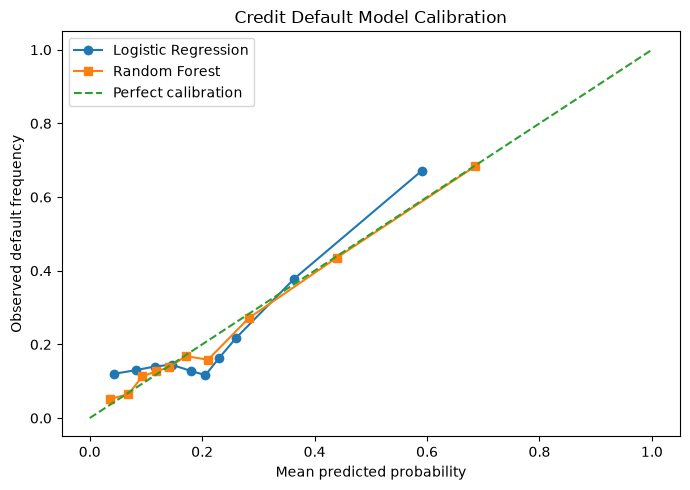

In [20]:

# Cell 15: Model calibration

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

print("Brier Scores (lower is better)")
print(
    "Logistic Regression:",
    round(brier_score_loss(y_test, y_prob), 4)
)
print(
    "Random Forest:",
    round(brier_score_loss(y_test, y_prob_rf), 4)
)

# Calculate calibration curves
observed_log, predicted_log = calibration_curve(
    y_test, y_prob, n_bins=10, strategy="quantile"
)

observed_rf, predicted_rf = calibration_curve(
    y_test, y_prob_rf, n_bins=10, strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    predicted_log, observed_log,
    marker="o", label="Logistic Regression"
)
plt.plot(
    predicted_rf, observed_rf,
    marker="s", label="Random Forest"
)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--", label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default frequency")
plt.title("Credit Default Model Calibration")
plt.legend()
plt.tight_layout()
plt.show()


,Feature,Importance,Std
5,PAY_1,0.0713,0.0032
0,LIMIT_BAL,0.0174,0.0016
6,PAY_2,0.0149,0.0031
11,BILL_AMT1,0.0107,0.0010
17,PAY_AMT1,0.0063,0.0015
7,PAY_3,0.0063,0.0024
19,PAY_AMT3,0.0045,0.0013
18,PAY_AMT2,0.0041,0.0011
10,PAY_6,0.0039,0.0028
8,PAY_4,0.0033,0.0030


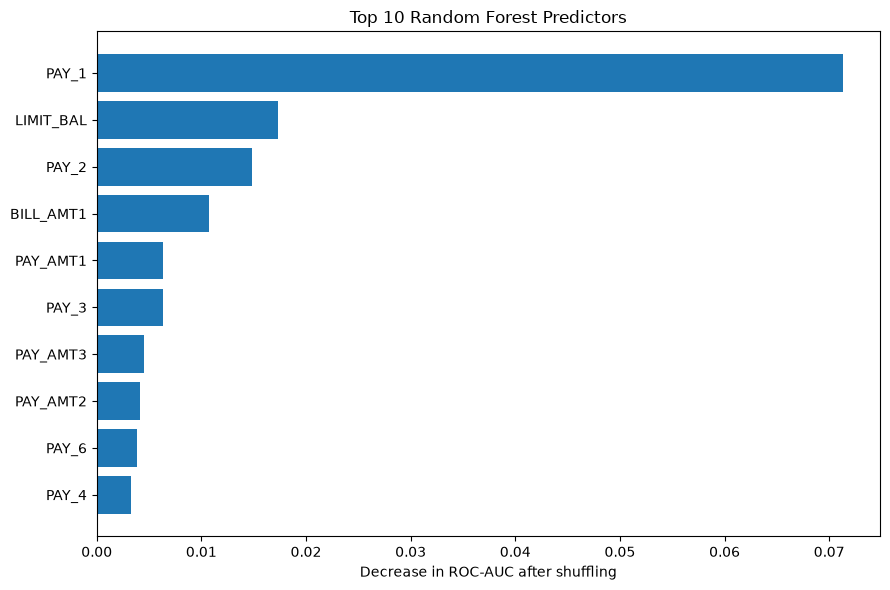

In [21]:

# Cell 16: Permutation importance for Random Forest

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_table = importance_table.sort_values(
    "Importance", ascending=False
)

display(importance_table.head(15).round(4))

# Plot the top 10 features
top_features = importance_table.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.title("Top 10 Random Forest Predictors")
plt.tight_layout()
plt.show()


In [22]:

# Cell 17: Save model evaluation results

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss
)

final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Brier Score"
    ],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        brier_score_loss(y_test, y_prob)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        roc_auc_score(y_test, y_prob_rf),
        brier_score_loss(y_test, y_prob_rf)
    ]
})

display(final_comparison.round(4))

final_comparison.to_csv(
    "credit_risk_model_comparison.csv",
    index=False
)

print("Comparison saved successfully!")


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8088,0.8153
1,Precision,0.6923,0.6515
2,Recall,0.2442,0.3549
3,F1 Score,0.3610,0.4595
4,ROC-AUC,0.7100,0.7704
5,Brier Score,0.1466,0.1362


Comparison saved successfully!


In [23]:

# Cell 18: Create training, validation and test sets

from sklearn.model_selection import train_test_split

# First, hold out 20% as the final test set
X_dev, X_final_test, y_dev, y_final_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=2026,
    stratify=y
)

# Split the remaining 80% into 60% training and 20% validation
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=2026,
    stratify=y_dev
)

print("Training set:", X_train_new.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_final_test.shape)

print("\nDefault rates:")
print("Training:", round(y_train_new.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_final_test.mean() * 100, 2), "%")


Training set: (18000, 23)
Validation set: (6000, 23)
Final test set: (6000, 23)

Default rates:
Training: 22.12 %
Validation: 22.12 %
Test: 22.12 %


In [24]:

# Cell 19: Retrain both models

logistic_model.fit(X_train_new, y_train_new)
rf_model.fit(X_train_new, y_train_new)

print("Both models retrained successfully.")


Both models retrained successfully.


In [25]:

# Cell 20: Validation predictions

val_prob_log = logistic_model.predict_proba(X_val)[:, 1]
val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

from sklearn.metrics import roc_auc_score, brier_score_loss

print("Validation ROC-AUC")
print("Logistic Regression:",
      round(roc_auc_score(y_val, val_prob_log), 4))
print("Random Forest:",
      round(roc_auc_score(y_val, val_prob_rf), 4))

print("\nValidation Brier score")
print("Logistic Regression:",
      round(brier_score_loss(y_val, val_prob_log), 4))
print("Random Forest:",
      round(brier_score_loss(y_val, val_prob_rf), 4))


Validation ROC-AUC
Logistic Regression: 0.7213
Random Forest: 0.7772

Validation Brier score
Logistic Regression: 0.1453
Random Forest: 0.1352


In [26]:

# Cell 21: Threshold analysis on validation data

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.15, 0.56, 0.05):
    val_pred = (val_prob_rf >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "Customers_Flagged": int(val_pred.sum())
    })

threshold_results_df = pd.DataFrame(threshold_results)
display(threshold_results_df.round(4))


,Threshold,Precision,Recall,F1 Score,Customers_Flagged
0,0.15,0.3370,0.8041,0.4750,3166
1,0.20,0.4093,0.6903,0.5139,2238
2,0.25,0.4798,0.6164,0.5396,1705
3,0.30,0.5313,0.5569,0.5438,1391
4,0.35,0.5668,0.4989,0.5307,1168
5,0.40,0.6081,0.4514,0.5182,985
6,0.45,0.6387,0.4077,0.4977,847
7,0.50,0.6562,0.3640,0.4683,736
8,0.55,0.6854,0.3120,0.4288,604


In [27]:

# Cell 22: Combine training and validation data

X_final_train = pd.concat(
    [X_train_new, X_val],
    axis=0
)

y_final_train = pd.concat(
    [y_train_new, y_val],
    axis=0
)

print("Final training data:", X_final_train.shape)
print("Final test data:", X_final_test.shape)


Final training data: (24000, 23)
Final test data: (6000, 23)


In [28]:

# Cell 23: Fit the final Random Forest model

final_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

final_rf_model.fit(X_final_train, y_final_train)

print("Final model fitted successfully.")


Final model fitted successfully.


In [29]:

# Cell 24: Final test evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

final_prob = final_rf_model.predict_proba(X_final_test)[:, 1]

selected_threshold = 0.30
final_pred = (final_prob >= selected_threshold).astype(int)

print("FINAL TEST RESULTS")
print("------------------")

print("Threshold:", selected_threshold)
print("Accuracy:", round(
    accuracy_score(y_final_test, final_pred), 4
))
print("Precision:", round(
    precision_score(y_final_test, final_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_final_test, final_pred, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_final_test, final_pred, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_final_test, final_prob), 4
))
print("Brier Score:", round(
    brier_score_loss(y_final_test, final_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_final_test, final_pred))

print("\nClassification Report:")
print(classification_report(
    y_final_test, final_pred, zero_division=0
))


FINAL TEST RESULTS
------------------
Threshold: 0.3
Accuracy: 0.7908
Precision: 0.5254
Recall: 0.5614
F1 Score: 0.5428
ROC-AUC: 0.7836
Brier Score: 0.1344

Confusion Matrix:
[[4000  673]
 [ 582  745]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      4673
           1       0.53      0.56      0.54      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.71      0.70      6000
weighted avg       0.80      0.79      0.79      6000



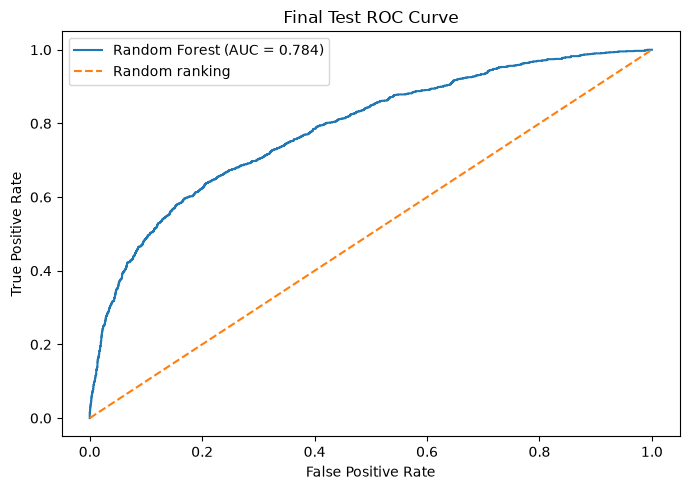

In [30]:

# Cell 25: Final ROC curve

from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_final_test, final_prob)
final_auc = roc_auc_score(y_final_test, final_prob)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {final_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Test ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


In [31]:

# Cell 26: Export predictions

final_predictions = pd.DataFrame({
    "Actual_Default": y_final_test,
    "Predicted_Default_Probability": final_prob,
    "Predicted_Default_Class": final_pred
}, index=y_final_test.index)

final_predictions.to_csv(
    "credit_risk_final_predictions.csv",
    index=True
)

print("Final predictions exported successfully.")


Final predictions exported successfully.


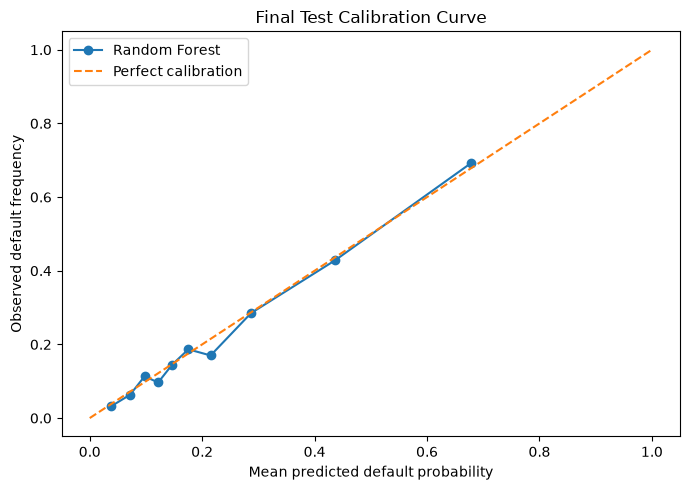

Final test Brier score: 0.1344


In [32]:

# Cell 27: Final test calibration curve

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

observed, predicted = calibration_curve(
    y_final_test,
    final_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(
    predicted,
    observed,
    marker="o",
    label="Random Forest"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted default probability")
plt.ylabel("Observed default frequency")
plt.title("Final Test Calibration Curve")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Final test Brier score:",
    round(brier_score_loss(y_final_test, final_prob), 4)
)


In [33]:

# Cell 28: Save final metrics and project summary

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)

metrics = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Brier Score"
    ],
    "Final_Test_Result": [
        accuracy_score(y_final_test, final_pred),
        precision_score(y_final_test, final_pred, zero_division=0),
        recall_score(y_final_test, final_pred, zero_division=0),
        f1_score(y_final_test, final_pred, zero_division=0),
        roc_auc_score(y_final_test, final_prob),
        brier_score_loss(y_final_test, final_prob)
    ]
}

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv("final_model_metrics.csv", index=False)

report = """
CREDIT RISK MODELLING AND DEFAULT PREDICTION

Objective
Estimate credit-card default probabilities using borrower
characteristics and historical repayment information.

Dataset
30,000 observations and 23 candidate predictors after removing
the customer ID and separating the target variable.
Target: dpnm (1 = default, 0 = non-default).

Methods
1. Exploratory data analysis
2. Logistic Regression baseline
3. Random Forest model
4. Training, validation and test split
5. Threshold selection on validation data
6. Final test evaluation

Final model
Random Forest classifier
Classification threshold: 0.30

Final test results
Accuracy: 0.7908
Precision: 0.5254
Recall: 0.5614
F1 Score: 0.5428
ROC-AUC: 0.7836
Brier Score: 0.1344

Confusion matrix
True negatives: 4000
False positives: 673
False negatives: 582
True positives: 745

Limitations
This is an educational model using historical credit-card data.
It is not a production-ready lending model. Further work should
include calibration analysis, temporal validation, model
stability, fairness assessment and business cost analysis.
"""

with open("credit_risk_project_report.txt", "w", encoding="utf-8") as f:
    f.write(report)

print("Saved final_model_metrics.csv")
print("Saved credit_risk_project_report.txt")

display(metrics_df.round(4))


Saved final_model_metrics.csv
Saved credit_risk_project_report.txt


,Metric,Final_Test_Result
0,Accuracy,0.7908
1,Precision,0.5254
2,Recall,0.5614
3,F1 Score,0.5428
4,ROC-AUC,0.7836
5,Brier Score,0.1344
